In [18]:
import pandas as pd
import matplotlib.pyplot as plt

#1. 设置数据文件路径

DATA_FILE = r"C:\Users\admin\ibtracs.ALL.list.v04r00.csv"

#2. 读取数据

df = pd.read_csv(
    DATA_FILE,
    usecols=range(17),
    skiprows=[1, 2],
    parse_dates=["ISO_TIME"],
    na_values=["NOT_NAMED", " "],
    low_memory=False,
)

df["NAME"] = df["NAME"].fillna("UNNAMED")
df["BASIN"] = df["BASIN"].fillna("UNKNOWN")
df["LAT"] = pd.to_numeric(df["LAT"], errors="coerce")
df["LON"] = pd.to_numeric(df["LON"], errors="coerce")
df["WMO_WIND"] = pd.to_numeric(df["WMO_WIND"], errors="coerce")

# 没有时间或位置的记录不能用于轨迹分析
df = df.dropna(subset=["ISO_TIME", "LAT", "LON"]).copy()

print("数据形状：", df.shape)
print("开始时间：", df["ISO_TIME"].min())
print("结束时间：", df["ISO_TIME"].max())

数据形状： (707176, 17)
开始时间： 1842-10-25 06:00:00
结束时间： 2022-10-13 00:00:00


In [ ]:
#3.1和3.2找出风速最大的风暴

In [19]:
#没有风速的记录不能参与比较
wind_data = df.dropna(subset=["WMO_WIND"]).copy()

#先按风速从大到小排序
wind_data = wind_data.sort_values(
    ["WMO_WIND", "ISO_TIME"],
    ascending=[False, True],
)

#同一个SID只保留第一行，也就是峰值那一行
storm_peak = wind_data.drop_duplicates(
    subset="SID",
    keep="first",
)

print("\n3.1 风速最大的 10 个风暴：")
print(
    storm_peak[
        ["SEASON", "NAME", "SID", "WMO_WIND"]
    ]
    .head(10)
    .to_string(index=False)
)

print("\n3.2 最强 20 个风暴的峰值风速：")
print(
    storm_peak["WMO_WIND"]
    .head(20)
    .to_string(index=False)
)


3.1 风速最大的 10 个风暴：
 SEASON     NAME           SID  WMO_WIND
   2015 PATRICIA 2015293N13266     185.0
   1980    ALLEN 1980214N11330     165.0
   1935  UNNAMED 1935241N23291     160.0
   1988  GILBERT 1988253N12306     160.0
   1997    LINDA 1997253N12255     160.0
   2005    WILMA 2005289N18282     160.0
   2019   DORIAN 2019236N10314     160.0
   1998    MITCH 1998295N12284     155.0
   2005     RITA 2005261N21290     155.0
   2009     RICK 2009288N07267     155.0

3.2 最强 20 个风暴的峰值风速：
185.0
165.0
160.0
160.0
160.0
160.0
160.0
155.0
155.0
155.0
155.0
150.0
150.0
150.0
150.0
150.0
150.0
150.0
150.0
150.0


In [20]:
#3.3 统计每个海盆有多少条数据
basin_counts = df["BASIN"].value_counts(dropna=False)

print("\n3.3 各海盆的数据点数量：")
print(basin_counts)


3.3 各海盆的数据点数量：
BASIN
WP         236576
SI         160668
UNKNOWN    124881
SP          67119
EP          62412
NI          55401
SA            119
Name: count, dtype: int64


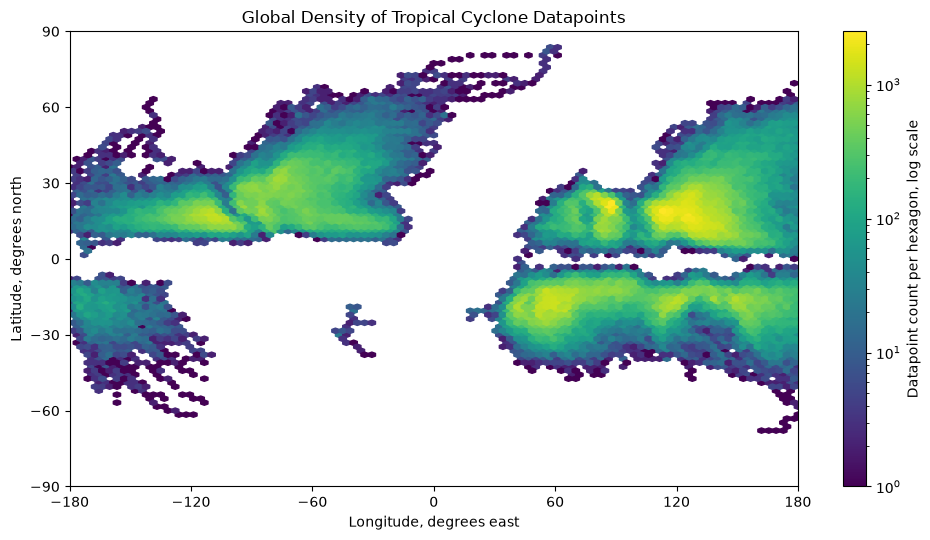

In [21]:
#3.4 绘制经纬度 hexbin 密度图

plt.figure(figsize=(10, 5.5))

hexbin = plt.hexbin(
    df["LON"],
    df["LAT"],
    gridsize=100,
    extent=(-180, 180, -90, 90),
    mincnt=1,
    bins="log",
    cmap="viridis",
)

plt.colorbar(
    hexbin,
    label="Datapoint count per hexagon, log scale",
)

plt.title("Global Density of Tropical Cyclone Datapoints")
plt.xlabel("Longitude, degrees east")
plt.ylabel("Latitude, degrees north")
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.xticks(range(-180, 181, 60))
plt.yticks(range(-90, 91, 30))
plt.tight_layout()
plt.show()


3.5 Mangkhut 数据点数量： 99
起点： 2018-09-06 12:00:00 11.8 170.2
终点： 2018-09-17 18:00:00 24.1 103.9
最大风速： 110.0


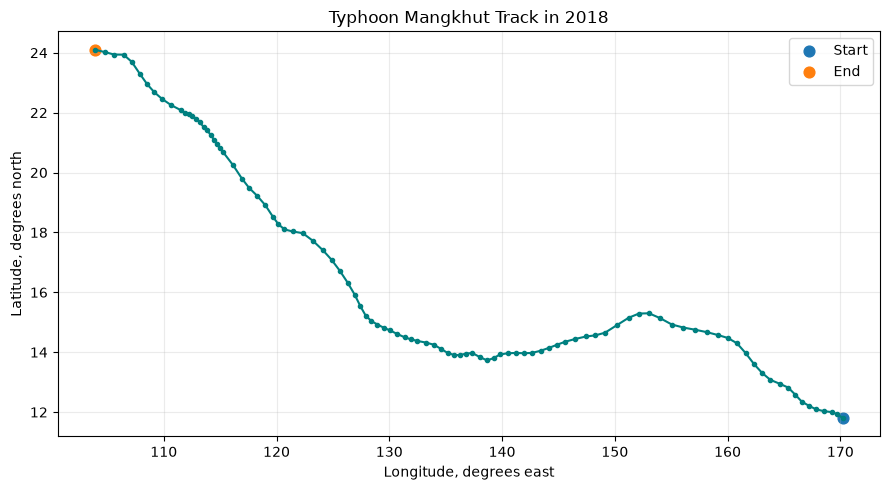

In [22]:
#3.5 绘制 2018 年 Mangkhut 的路径

mangkhut = df[
    (df["SEASON"] == 2018)
    & (df["NAME"].str.upper() == "MANGKHUT")
].copy()

# 不排序的话，轨迹线可能乱连
mangkhut = mangkhut.sort_values("ISO_TIME")

if mangkhut.empty:
    raise ValueError("没有找到 2018 年的 Mangkhut")

start = mangkhut.iloc[0]
end = mangkhut.iloc[-1]

print("\n3.5 Mangkhut 数据点数量：", len(mangkhut))
print("起点：", start["ISO_TIME"], start["LAT"], start["LON"])
print("终点：", end["ISO_TIME"], end["LAT"], end["LON"])
print("最大风速：", mangkhut["WMO_WIND"].max())

plt.figure(figsize=(9, 5))

plt.plot(
    mangkhut["LON"],
    mangkhut["LAT"],
    color="teal",
    marker="o",
    markersize=3,
    linewidth=1.5,
)

plt.scatter(start["LON"], start["LAT"], s=60, label="Start")
plt.scatter(end["LON"], end["LAT"], s=60, label="End")

plt.title("Typhoon Mangkhut Track in 2018")
plt.xlabel("Longitude, degrees east")
plt.ylabel("Latitude, degrees north")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
#3.6 筛选 1970 年以来的 WP 和 EP

filtered = df[
    (df["SEASON"] >= 1970)
    & df["BASIN"].isin(["WP", "EP"])
].copy()

print("\n3.6 筛选后的数据形状：", filtered.shape)
print(filtered["BASIN"].value_counts())


3.6 筛选后的数据形状： (176352, 17)
BASIN
WP    122301
EP     54051
Name: count, dtype: int64



3.7 每日数据点数量统计：
count    19229.000000
mean         9.171148
std         11.148994
min          0.000000
25%          0.000000
50%          8.000000
75%         16.000000
max         75.000000
Name: daily_count, dtype: float64


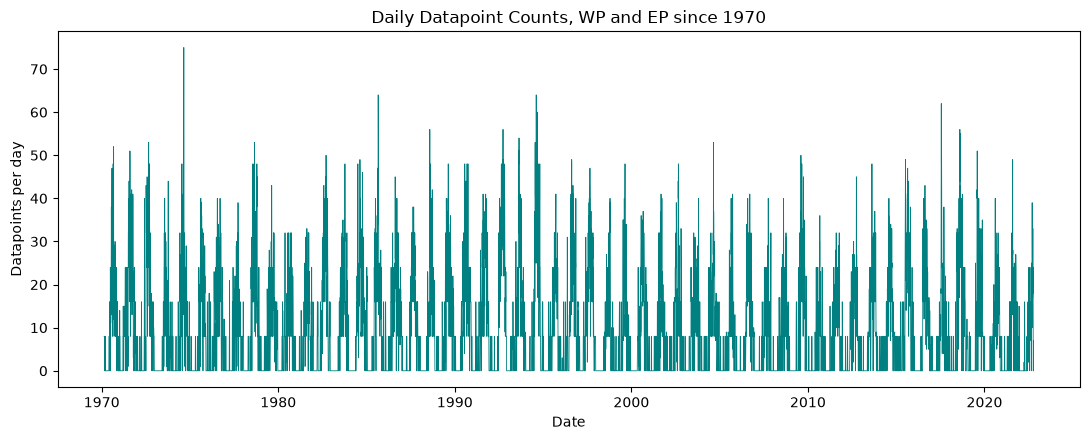

In [26]:
#3.7 统计每天有多少个数据点

# 把时间设为索引，才能使用 resample
filtered = filtered.set_index("ISO_TIME")

# D 表示按日分组，size() 表示统计每组有多少行
daily_counts = filtered.resample("D").size()
daily_counts.name = "daily_count"

print("\n3.7 每日数据点数量统计：")
print(daily_counts.describe())


# 建立一张简单的日数据表
daily = pd.DataFrame({
    "date": daily_counts.index,
    "count": daily_counts.values,
})

plt.figure(figsize=(11, 4.5))
plt.plot(daily["date"], daily["count"], linewidth=0.6, color="teal")
plt.title("Daily Datapoint Counts, WP and EP since 1970")
plt.xlabel("Date")
plt.ylabel("Datapoints per day")
plt.tight_layout()
plt.show()


3.8 气候态最大值：
day_of_year = 222
平均值 = 26.62264150943396


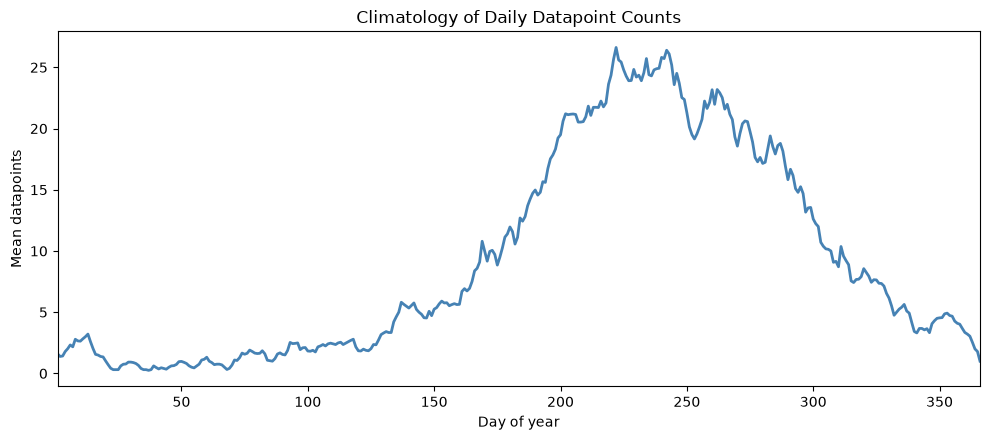

In [27]:
#3.8 按 day of year 计算气候态

# dayofyear：1 月 1 日是 1，12 月 31 日是 365 或 366
daily["day_of_year"] = daily["date"].dt.dayofyear

# 把所有年份中同一个日序的计数求平均
climatology = daily.groupby("day_of_year")["count"].mean()

print("\n3.8 气候态最大值：")
print("day_of_year =", climatology.idxmax())
print("平均值 =", climatology.max())

plt.figure(figsize=(10, 4.5))
plt.plot(
    climatology.index,
    climatology.values,
    color="steelblue",
    linewidth=2,
)

plt.title("Climatology of Daily Datapoint Counts")
plt.xlabel("Day of year")
plt.ylabel("Mean datapoints")
plt.xlim(1, 366)
plt.tight_layout()
plt.show()


3.9 逐日异常统计：
count    19229.000000
mean         0.000000
std          7.389795
min        -26.094340
25%         -3.584906
50%         -1.019231
75%          3.500000
max         50.113208
Name: anomaly, dtype: float64


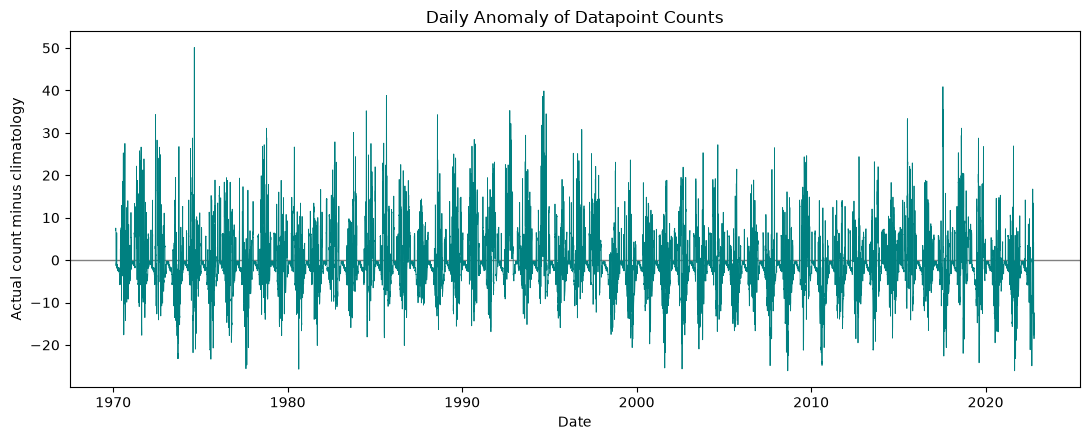

In [28]:
#3.9 计算逐日异常

# 找出每一天对应的气候态
daily["climatology"] = daily["day_of_year"].map(climatology)

# 异常 = 当天实际值 - 同一天序的气候态
daily["anomaly"] = daily["count"] - daily["climatology"]

print("\n3.9 逐日异常统计：")
print(daily["anomaly"].describe())

plt.figure(figsize=(11, 4.5))
plt.axhline(0, color="gray", linewidth=1)
plt.plot(
    daily["date"],
    daily["anomaly"],
    color="teal",
    linewidth=0.6,
)

plt.title("Daily Anomaly of Datapoint Counts")
plt.xlabel("Date")
plt.ylabel("Actual count minus climatology")
plt.tight_layout()
plt.show()


3.10 年度异常最高的 5 年：
      date  annual_anomaly  year
1992-01-01        4.537501  1992
1994-01-01        4.415686  1994
1997-01-01        3.330754  1997
1990-01-01        3.073220  1990
2015-01-01        3.067741  2015

3.10 年度异常最低的 5 年：
      date  annual_anomaly  year
2010-01-01       -4.570616  2010
1998-01-01       -2.830890  1998
2021-01-01       -2.751437  2021
2007-01-01       -2.562396  2007
1973-01-01       -2.556917  1973


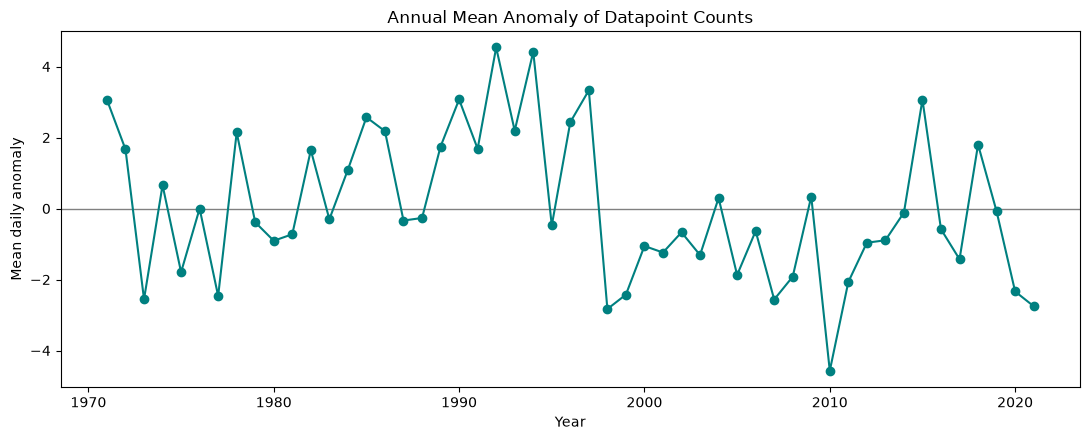

In [29]:
# 3.10 计算年度异常并画图

# 把日期设回索引，再按年求平均异常
daily_by_date = daily.set_index("date")

annual_anomaly = daily_by_date["anomaly"].resample("YS").mean()

# 统计每年有多少天
days_per_year = daily_by_date.groupby(daily_by_date.index.year).size()

# 只有至少 360 天的年份才参与排名
complete_years = days_per_year[days_per_year >= 360].index

annual_complete = annual_anomaly[
    annual_anomaly.index.year.isin(complete_years)
]

# 把年度 Series 转成表格，方便查看
annual_table = annual_complete.reset_index()
annual_table.columns = ["date", "annual_anomaly"]
annual_table["year"] = annual_table["date"].dt.year

print("\n3.10 年度异常最高的 5 年：")
print(
    annual_table
    .sort_values("annual_anomaly", ascending=False)
    .head(5)
    .to_string(index=False)
)

print("\n3.10 年度异常最低的 5 年：")
print(
    annual_table
    .sort_values("annual_anomaly")
    .head(5)
    .to_string(index=False)
)

plt.figure(figsize=(11, 4.5))
plt.axhline(0, color="gray", linewidth=1)

plt.plot(
    annual_complete.index.year,
    annual_complete.values,
    color="teal",
    marker="o",
    linewidth=1.5,
)

plt.title("Annual Mean Anomaly of Datapoint Counts")
plt.xlabel("Year")
plt.ylabel("Mean daily anomaly")
plt.tight_layout()
plt.show()